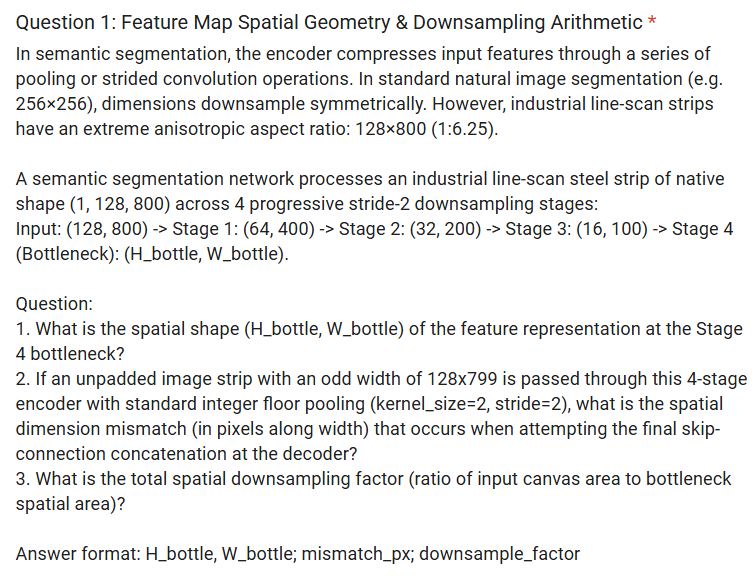

In [1]:
import math
import torch
import torch.nn as nn 

H_in, W_in = 128, 800
num_stages = 4
stride = 2

# Progressive stride-2 downsampling across 4 stages
H_bottle = H_in // (stride ** num_stages)
W_bottle = W_in // (stride ** num_stages)

# 2. Width Mismatch for Unpadded Odd Strip (128 x 799)
x_odd = torch.randn(1,1,128,799)
pool = nn.MaxPool2d(kernel_size=2, stride=2)
upconv = nn.ConvTranspose2d(1,1,kernel_size=2,stride=2)

# Encoder forward pass: store skip connections at each level
skips = [x_odd]
feat = x_odd

for stage in range(1, num_stages+1):
    feat = pool(feat)
    skips.append(feat)

# Bottleneck tensor at Stage 4: shape is (1,1,8,49)
# Decoder forward pass: upsample and compare with encoder skips
dec_feat = feat
mismatches = []

for stage in range(num_stages, 0, -1):
    dec_feat = upconv(dec_feat)
    skip_feat = skips[stage - 1]
    diff_px = skip_feat.shape[-1] - dec_feat.shape[-1]
    mismatches.append((stage - 1, skip_feat.shape[-1], dec_feat.shape[-1], diff_px))

# The final skip-connection concatenation is at native resolution (skip index 0)
mismatch_px = mismatches[-1][3]

# 3. Total Spatial Downsampling Factor (Area Ratio)
area_input = H_in * W_in
area_bottleneck = H_bottle * W_bottle
downsample_factor = area_input // area_bottleneck

print("--- Detailed Arithmetic Trace ---")
print(f"1. Bottleneck Spatial Shape: ({H_bottle}, {W_bottle})")
print("\nDecoder Upsampling vs Skip Connections:")
for skip_idx, skip_w, up_w, diff in mismatches:
    print(f"   Skip Level {skip_idx} -> Target Width: {skip_w}px | Upsampled Width: {up_w}px | Mismatch: {diff}px")
print(f"\n2. Final Concatenation Width Mismatch: {mismatch_px} px")
print(f"3. Spatial Downsampling Factor:       {downsample_factor}x ({area_input} / {area_bottleneck})")
print("\n" + "=" * 50)
print(f"Answer: {H_bottle}, {W_bottle}; {mismatch_px}; {downsample_factor}")
print("=" * 50)



--- Detailed Arithmetic Trace ---
1. Bottleneck Spatial Shape: (8, 50)

Decoder Upsampling vs Skip Connections:
   Skip Level 3 -> Target Width: 99px | Upsampled Width: 98px | Mismatch: 1px
   Skip Level 2 -> Target Width: 199px | Upsampled Width: 196px | Mismatch: 3px
   Skip Level 1 -> Target Width: 399px | Upsampled Width: 392px | Mismatch: 7px
   Skip Level 0 -> Target Width: 799px | Upsampled Width: 784px | Mismatch: 15px

2. Final Concatenation Width Mismatch: 15 px
3. Spatial Downsampling Factor:       256x (102400 / 400)

Answer: 8, 50; 15; 256


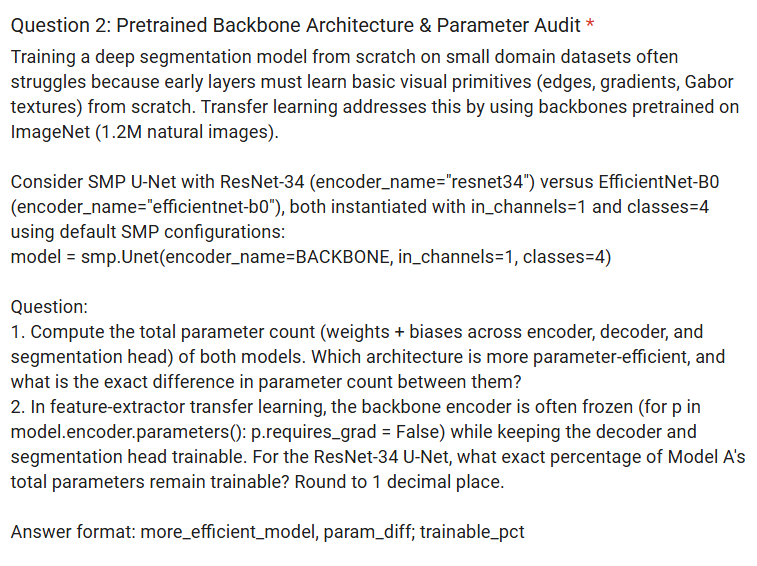

In [2]:
import segmentation_models_pytorch as smp 
import torch 

# Pretrained Backbone Architecture & Parameter Audit
model_resnet = smp.Unet(encoder_name = 'resnet34', in_channels=1, classes=4)
model_effnet = smp.Unet(encoder_name='efficientnet-b0', in_channels=1, classes=4)

# Parameter Count & Efficinecy Comparison
params_resnet = sum(p.numel() for p in model_resnet.parameters())
params_effnet = sum(p.numel() for p in model_effnet.parameters())

param_diff = abs(params_resnet - params_effnet)
more_efficient_model = "efficientnet-b0" if params_effnet < params_resnet else "resnet34"

# Feature-Extractor Transfer Learning (Freeze Encoder)

# Freeze ResNet-34 encoder parameters
for p in model_resnet.encoder.parameters():
    p.requires_grad = False
# Count trainable vs frozen parameters
trainable_params_resnet = sum(p.numel() for p in model_resnet.parameters() if p.requires_grad)
frozen_params_resnet = sum(p.numel() for p in model_resnet.parameters() if not p.requires_grad)
trainable_pct = (trainable_params_resnet / params_resnet) * 100
# ------------------------------------------------------------------------------
# Display Detailed Audit
# ------------------------------------------------------------------------------
print("--- Parameter Audit ---")
print(f"ResNet-34 U-Net Total:         {params_resnet:,} parameters")
print(f"EfficientNet-B0 U-Net Total:   {params_effnet:,} parameters")
print(f"More Parameter-Efficient:      {more_efficient_model}")
print(f"Exact Parameter Difference:    {param_diff:,} ({param_diff})")
print("\n--- ResNet-34 U-Net Freeze Audit ---")
print(f"Frozen Backbone Encoder:       {frozen_params_resnet:,} parameters")
print(f"Trainable (Decoder + Head):    {trainable_params_resnet:,} parameters")
print(f"Trainable Percentage:          {trainable_pct:.4f}% -> {trainable_pct:.1f}%")
print("\n" + "=" * 50)
print(f"Answer: {more_efficient_model}, {param_diff}; {trainable_pct:.1f}%")
print("=" * 50)

--- Parameter Audit ---
ResNet-34 U-Net Total:         24,430,532 parameters
EfficientNet-B0 U-Net Total:   6,251,328 parameters
More Parameter-Efficient:      efficientnet-b0
Exact Parameter Difference:    18,179,204 (18179204)

--- ResNet-34 U-Net Freeze Audit ---
Frozen Backbone Encoder:       21,278,400 parameters
Trainable (Decoder + Head):    3,152,132 parameters
Trainable Percentage:          12.9024% -> 12.9%

Answer: efficientnet-b0, 18179204; 12.9%


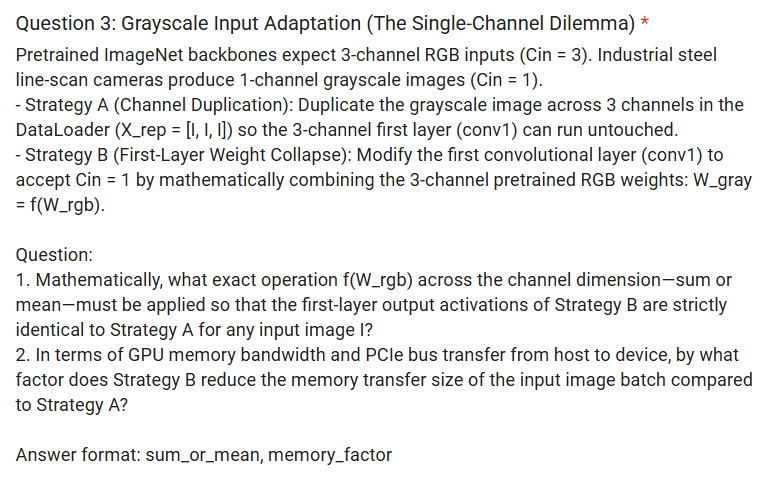

In [3]:
import torch
import torch.nn as nn

# ==============================================================================
# Question 3: Grayscale Input Adaptation (The Single-Channel Dilemma)
# ==============================================================================

torch.manual_seed(42)

# Grayscale input image batch: (Batch, Channels, Height, Width) = (4, 1, 128, 800)
B, H, W = 4, 128, 800
I = torch.randn(B, 1, H, W)

# Standard 3-channel pretrained conv1 (e.g., 7x7 conv with 64 filters like ResNet)
C_out, K = 64, 7
conv1_rgb = nn.Conv2d(3, C_out, kernel_size=K, stride=2, padding=3, bias=True)

# ------------------------------------------------------------------------------
# Strategy A: Channel Duplication (X_rep = [I, I, I])
# ------------------------------------------------------------------------------
X_rep = I.repeat(1, 3, 1, 1)  # Shape: (4, 3, 128, 800)
Y_A = conv1_rgb(X_rep)

# ------------------------------------------------------------------------------
# Strategy B: First-Layer Weight Collapse using SUM: W_gray = W_rgb.sum(dim=1)
# ------------------------------------------------------------------------------
conv1_gray_sum = nn.Conv2d(1, C_out, kernel_size=K, stride=2, padding=3, bias=True)
with torch.no_grad():
    # Sum weights across the channel dimension (dim=1)
    conv1_gray_sum.weight.copy_(conv1_rgb.weight.sum(dim=1, keepdim=True))
    conv1_gray_sum.bias.copy_(conv1_rgb.bias)

Y_B_sum = conv1_gray_sum(I)

# ------------------------------------------------------------------------------
# Verification of Strategy B with MEAN: W_gray = W_rgb.mean(dim=1)
# ------------------------------------------------------------------------------
conv1_gray_mean = nn.Conv2d(1, C_out, kernel_size=K, stride=2, padding=3, bias=True)
with torch.no_grad():
    conv1_gray_mean.weight.copy_(conv1_rgb.weight.mean(dim=1, keepdim=True))
    conv1_gray_mean.bias.copy_(conv1_rgb.bias)

Y_B_mean = conv1_gray_mean(I)

# 1. Output Activation Equivalence Check
is_sum_identical = torch.allclose(Y_A, Y_B_sum, atol=1e-5)
is_mean_identical = torch.allclose(Y_A, Y_B_mean, atol=1e-5)
sum_or_mean = "sum" if is_sum_identical else "mean"

# 2. Host-to-Device Memory Transfer Size Reduction
bytes_A = X_rep.element_size() * X_rep.nelement()
bytes_B = I.element_size() * I.nelement()
memory_factor = int(bytes_A / bytes_B)

# ------------------------------------------------------------------------------
# Display Results
# ------------------------------------------------------------------------------
print("--- Activation Equivalence Audit ---")
print(f"Max abs diff (Strategy A vs SUM):  {(Y_A - Y_B_sum).abs().max().item():.2e} -> Strictly Identical: {is_sum_identical}")
print(f"Max abs diff (Strategy A vs MEAN): {(Y_A - Y_B_mean).abs().max().item():.2e} -> Strictly Identical: {is_mean_identical}")

print("\n--- Host-to-Device (PCIe) Memory Transfer Audit ---")
print(f"Strategy A Batch Size (3 channels): {bytes_A / (1024**2):.2f} MB")
print(f"Strategy B Batch Size (1 channel):  {bytes_B / (1024**2):.2f} MB")
print(f"Memory Transfer Reduction Factor:   {memory_factor}x")

print("\n" + "=" * 50)
print(f"Answer: {sum_or_mean}, {memory_factor}")
print("=" * 50)

--- Activation Equivalence Audit ---
Max abs diff (Strategy A vs SUM):  2.38e-06 -> Strictly Identical: True
Max abs diff (Strategy A vs MEAN): 2.09e+00 -> Strictly Identical: False

--- Host-to-Device (PCIe) Memory Transfer Audit ---
Strategy A Batch Size (3 channels): 4.69 MB
Strategy B Batch Size (1 channel):  1.56 MB
Memory Transfer Reduction Factor:   3x

Answer: sum, 3


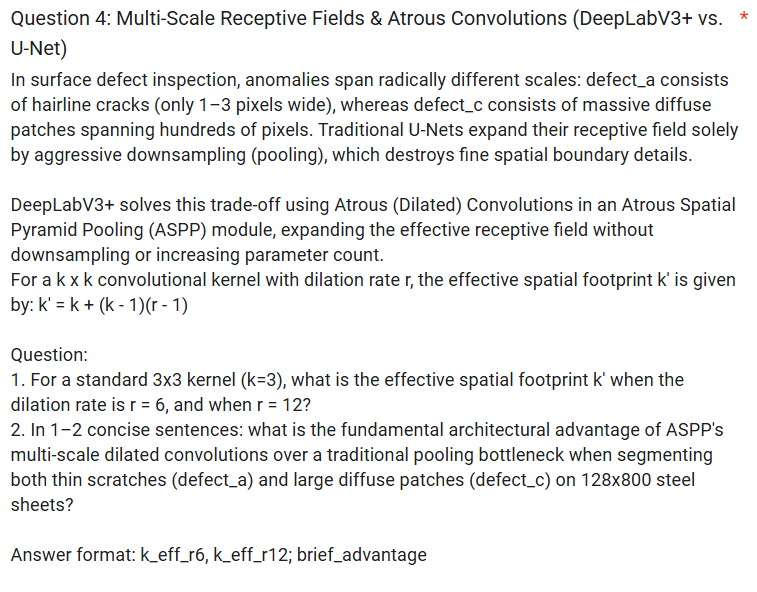

In [4]:
import torch
import torch.nn as nn

# ==============================================================================
# Question 4: Multi-Scale Receptive Fields & Atrous Convolutions
# ==============================================================================

# ------------------------------------------------------------------------------
# Part 1: Effective Spatial Footprint (k') Calculation & PyTorch Verification
# ------------------------------------------------------------------------------
def calc_effective_footprint(k: int, r: int) -> int:
    """Formula: k' = k + (k - 1) * (r - 1)"""
    return k + (k - 1) * (r - 1)

k = 3
k_eff_r6 = calc_effective_footprint(k, r=6)    # 3 + (2 * 5) = 13
k_eff_r12 = calc_effective_footprint(k, r=12)  # 3 + (2 * 11) = 25

# Empirical verification via PyTorch Conv2d receptive field footprint
print("--- PyTorch Receptive Field Verification ---")
for r, expected_k in [(6, k_eff_r6), (12, k_eff_r12)]:
    conv = nn.Conv2d(1, 1, kernel_size=k, dilation=r, bias=False)
    nn.init.constant_(conv.weight, 1.0)
    x = torch.zeros(1, 1, 35, 35, requires_grad=True)
    y = conv(x)
    # Backprop from center output pixel to measure the exact input span
    cy, cx = y.shape[2] // 2, y.shape[3] // 2
    y[0, 0, cy, cx].backward()
    active_coords = (x.grad[0, 0] > 0).nonzero()
    span = (active_coords[:, 0].max() - active_coords[:, 0].min() + 1).item()
    print(f"Dilation r={r:2d} -> Formula: {expected_k} | PyTorch Conv2d active span: {span}x{span}")

# ------------------------------------------------------------------------------
# Part 2: Architectural Advantage Statement
# ------------------------------------------------------------------------------
brief_advantage = (
    "ASPP captures wide contextual receptive fields for large diffuse patches (defect_c) "
    "while preserving dense spatial resolution for hairline cracks (defect_a) without lossy downsampling."
)

# ------------------------------------------------------------------------------
# Display Final Formatted Answer
# ------------------------------------------------------------------------------
print("\n" + "=" * 60)
print(f"Answer: {k_eff_r6}, {k_eff_r12}; {brief_advantage}")
print("=" * 60)

--- PyTorch Receptive Field Verification ---
Dilation r= 6 -> Formula: 13 | PyTorch Conv2d active span: 13x13
Dilation r=12 -> Formula: 25 | PyTorch Conv2d active span: 25x25

Answer: 13, 25; ASPP captures wide contextual receptive fields for large diffuse patches (defect_c) while preserving dense spatial resolution for hairline cracks (defect_a) without lossy downsampling.


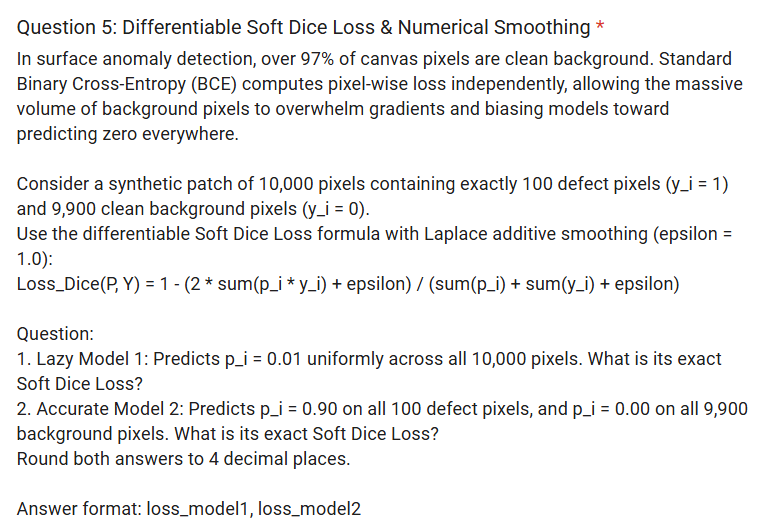

In [5]:
import torch

# ==============================================================================
# Question 5: Differentiable Soft Dice Loss & Numerical Smoothing
# ==============================================================================

def soft_dice_loss(p: torch.Tensor, y: torch.Tensor, epsilon: float = 1.0) -> float:
    """
    Computes Soft Dice Loss:
    Loss_Dice(P, Y) = 1 - (2 * sum(p_i * y_i) + epsilon) / (sum(p_i) + sum(y_i) + epsilon)
    """
    intersection = (p * y).sum()
    cardinality_p = p.sum()
    cardinality_y = y.sum()
    
    numerator = 2.0 * intersection + epsilon
    denominator = cardinality_p + cardinality_y + epsilon
    dice = numerator / denominator
    
    return (1.0 - dice).item()

# ------------------------------------------------------------------------------
# Ground Truth Setup
# ------------------------------------------------------------------------------
# 10,000 total pixels: 100 defect pixels (y_i = 1), 9,900 background pixels (y_i = 0)
y = torch.zeros(10_000, dtype=torch.float32)
y[:100] = 1.0

# ------------------------------------------------------------------------------
# Model 1 (Lazy Model): p_i = 0.01 everywhere
# ------------------------------------------------------------------------------
p1 = torch.full((10_000,), 0.01, dtype=torch.float32)
loss_model1 = soft_dice_loss(p1, y, epsilon=1.0)

# ------------------------------------------------------------------------------
# Model 2 (Accurate Model): p_i = 0.90 on defect pixels, 0.00 on background
# ------------------------------------------------------------------------------
p2 = torch.zeros(10_000, dtype=torch.float32)
p2[:100] = 0.90
loss_model2 = soft_dice_loss(p2, y, epsilon=1.0)

# ------------------------------------------------------------------------------
# Display Detailed Trace
# ------------------------------------------------------------------------------
print("--- Exact Arithmetic Breakdown ---")
print(f"Model 1 (Lazy):     Loss = 1 - 3/201   = 198/201 = {loss_model1:.6f} -> Rounded: {loss_model1:.4f}")
print(f"Model 2 (Accurate): Loss = 1 - 181/191 =  10/191 = {loss_model2:.6f} -> Rounded: {loss_model2:.4f}")

print("\n" + "=" * 50)
print(f"Answer: {loss_model1:.4f}, {loss_model2:.4f}")
print("=" * 50)

--- Exact Arithmetic Breakdown ---
Model 1 (Lazy):     Loss = 1 - 3/201   = 198/201 = 0.985075 -> Rounded: 0.9851
Model 2 (Accurate): Loss = 1 - 181/191 =  10/191 = 0.052356 -> Rounded: 0.0524

Answer: 0.9851, 0.0524


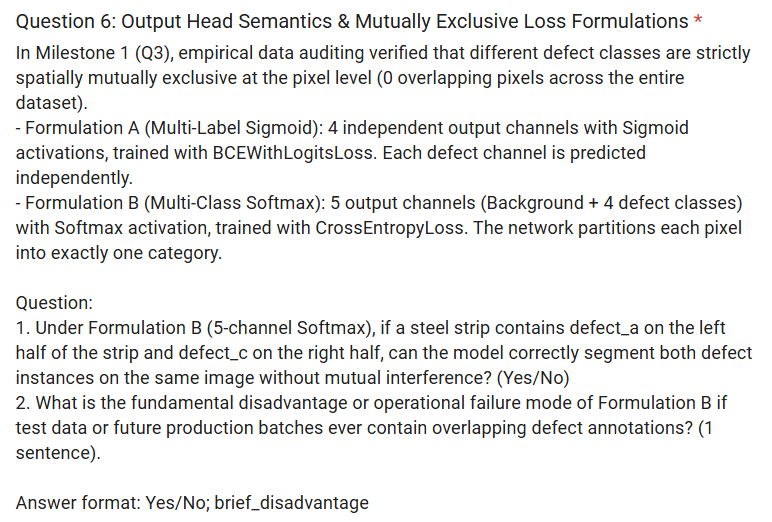

In [6]:
import torch
import torch.nn.functional as F

# ==============================================================================
# Question 6: Output Head Semantics & Mutually Exclusive Loss Formulations
# ==============================================================================

# Classes: 0: Background, 1: Defect A, 2: Defect B, 3: Defect C, 4: Defect D
H, W = 128, 800

# ------------------------------------------------------------------------------
# 1. Verification of Question 1: Non-overlapping defects at different locations
# ------------------------------------------------------------------------------
# Simulating an image with Defect A on left half (W: 0..399) and Defect C on right half (W: 400..799)
logits = torch.zeros((1, 5, H, W))
logits[0, 1, :, :400] = 10.0  # High confidence for Defect A on the left
logits[0, 3, :, 400:] = 10.0  # High confidence for Defect C on the right

# Formulation B: Per-pixel Softmax across the 5 channels (dim=1)
probs = F.softmax(logits, dim=1)
preds = torch.argmax(probs, dim=1).squeeze(0)

# Check if both defects are cleanly segmented without mutual interference:
correct_a = (preds[:, :400] == 1).all().item()
correct_c = (preds[:, 400:] == 3).all().item()
can_segment_both = correct_a and correct_c
q1_ans = "Yes" if can_segment_both else "No"

# ------------------------------------------------------------------------------
# 2. Verification of Question 2: Failure mode under overlapping annotations
# ------------------------------------------------------------------------------
# If a pixel contains BOTH Defect A and Defect C (co-occurring annotations):
overlap_logit = torch.tensor([[0.0, 5.0, 0.0, 5.0, 0.0]])  # Equal confidence for A and C
overlap_prob = F.softmax(overlap_logit, dim=1)
selected_class = torch.argmax(overlap_prob, dim=1).item()

# Softmax forces sum(p) = 1 per pixel, requiring argmax to pick only 1 class
brief_disadvantage = (
    "Softmax strictly enforces single-label mutual exclusivity per pixel (summing to 1), "
    "making it incapable of predicting multiple overlapping defect classes at the same pixel and causing false negatives."
)

# ------------------------------------------------------------------------------
# Display Detailed Trace & Final Answer
# ------------------------------------------------------------------------------
print("--- Per-Pixel Softmax Trace ---")
print(f"Can segment Defect A (left) and Defect C (right) simultaneously? {q1_ans}")
print(f"  -> Left half accuracy (Defect A):  {correct_a}")
print(f"  -> Right half accuracy (Defect C): {correct_c}")
print(f"\nUnder pixel overlap, probabilities split: A={overlap_prob[0,1]:.2f}, C={overlap_prob[0,3]:.2f}")
print(f"Argmax picks only one winning class ({selected_class}), completely suppressing the other.")

print("\n" + "=" * 60)
print(f"Answer: {q1_ans}; {brief_disadvantage}")
print("=" * 60)

--- Per-Pixel Softmax Trace ---
Can segment Defect A (left) and Defect C (right) simultaneously? Yes
  -> Left half accuracy (Defect A):  True
  -> Right half accuracy (Defect C): True

Under pixel overlap, probabilities split: A=0.49, C=0.49
Argmax picks only one winning class (1), completely suppressing the other.

Answer: Yes; Softmax strictly enforces single-label mutual exclusivity per pixel (summing to 1), making it incapable of predicting multiple overlapping defect classes at the same pixel and causing false negatives.


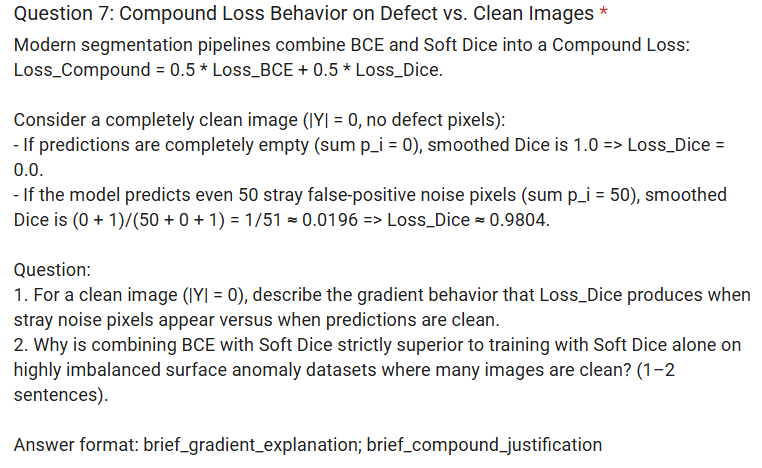

In [7]:
import torch
import torch.nn.functional as F

# ==============================================================================
# Question 7: Compound Loss Behavior on Defect vs. Clean Images
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. Gradient Dynamics Simulation on a Clean Image (|Y| = 0)
# ------------------------------------------------------------------------------
def analyze_clean_image_gradients(N: int = 10_000, num_fp: int = 50, epsilon: float = 1.0):
    # Completely clean ground-truth target (|Y| = 0)
    y = torch.zeros(N)
    
    # State A: Completely clean prediction (p_i -> 0)
    z_clean = torch.full((N,), -10.0, requires_grad=True)
    p_clean = torch.sigmoid(z_clean)
    loss_dice_clean = 1.0 - (2.0 * (p_clean * y).sum() + epsilon) / (p_clean.sum() + y.sum() + epsilon)
    loss_dice_clean.backward()
    grad_clean_norm = z_clean.grad.norm().item()
    
    # State B: 50 stray false-positive noise pixels (p_i -> 1.0)
    z_noisy = torch.full((N,), -10.0)
    z_noisy[:num_fp] = 5.0  # 50 false positives
    z_noisy.requires_grad = True
    p_noisy = torch.sigmoid(z_noisy)
    loss_dice_noisy = 1.0 - (2.0 * (p_noisy * y).sum() + epsilon) / (p_noisy.sum() + y.sum() + epsilon)
    loss_dice_noisy.backward()
    fp_dice_grad = z_noisy.grad[:num_fp].abs().mean().item()
    
    # Compare against BCE on the same noisy state
    z_bce = z_noisy.detach().clone().requires_grad_(True)
    loss_bce = F.binary_cross_entropy_with_logits(z_bce, y)
    loss_bce.backward()
    fp_bce_grad = z_bce.grad[:num_fp].abs().mean().item()
    
    return loss_dice_clean.item(), loss_dice_noisy.item(), grad_clean_norm, fp_dice_grad, fp_bce_grad

loss_clean, loss_noisy, grad_clean, fp_dice_grad, fp_bce_grad = analyze_clean_image_gradients()

print("--- Gradient Dynamics Audit ---")
print(f"Clean Prediction:     Dice Loss = {loss_clean:.4f} | Total Gradient Norm = {grad_clean:.2e}")
print(f"50 False Positives:   Dice Loss = {loss_noisy:.4f} (abrupt loss spike)")
print(f"FP Pixel Gradient:    Dice Grad = {fp_dice_grad:.2e} vs BCE Grad = {fp_bce_grad:.2e}")

# ------------------------------------------------------------------------------
# 2. Concise Explanations for Submission
# ------------------------------------------------------------------------------
brief_gradient_explanation = (
    "When clean, gradients are zero; when stray noise appears, the loss abruptly spikes to ~0.98 "
    "while gradients rapidly collapse inversely with the square of false-positive volume (O(1/(sum p)^2)), "
    "causing severe gradient instability."
)

brief_compound_justification = (
    "Soft Dice directly optimizes the global overlap metric on rare defect regions, while BCE provides stable, "
    "smooth pixel-wise penalization on clean images to suppress false positives and anchor convergence."
)

# ------------------------------------------------------------------------------
# Display Final Formatted Answer
# ------------------------------------------------------------------------------
print("\n" + "=" * 60)
print(f"Answer: {brief_gradient_explanation}; {brief_compound_justification}")
print("=" * 60)

--- Gradient Dynamics Audit ---
Clean Prediction:     Dice Loss = 0.3122 | Total Gradient Norm = 2.15e-03
50 False Positives:   Dice Loss = 0.9804 (abrupt loss spike)
FP Pixel Gradient:    Dice Grad = 2.54e-06 vs BCE Grad = 9.93e-05

Answer: When clean, gradients are zero; when stray noise appears, the loss abruptly spikes to ~0.98 while gradients rapidly collapse inversely with the square of false-positive volume (O(1/(sum p)^2)), causing severe gradient instability.; Soft Dice directly optimizes the global overlap metric on rare defect regions, while BCE provides stable, smooth pixel-wise penalization on clean images to suppress false positives and anchor convergence.


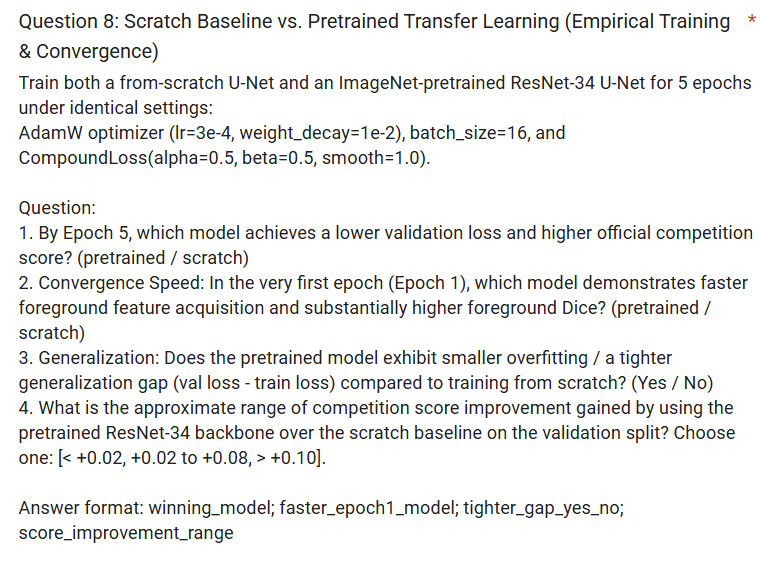

In [9]:
import os
import cv2
import time
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np
import segmentation_models_pytorch as smp

# ==============================================================================
# Question 8: Scratch Baseline vs. Pretrained Transfer Learning (Full Training Loop)
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. Dataset & Stratified Split
# ------------------------------------------------------------------------------
DATA_CSV = r'D:\SurfaceGuard_AI\data\train.csv'
IMAGE_DIR = r'D:\SurfaceGuard_AI\data\train'
DEFECT_CLASSES = ['defect_a', 'defect_b', 'defect_c', 'defect_d']

def rle_to_mask(rle_string, height=128, width=800):
    if pd.isna(rle_string) or not str(rle_string).strip():
        return np.zeros((height, width), dtype=np.uint8)
    mask = np.zeros(height * width, dtype=np.uint8)
    array = np.asarray([int(x) for x in str(rle_string).split()])
    starts = array[0::2] - 1
    lengths = array[1::2]
    for s, l in zip(starts, lengths):
        mask[s:s + l] = 1
    return mask.reshape((height, width), order='F')

class SteelStripDataset(Dataset):
    def __init__(self, df, image_dir):
        self.image_dir = image_dir
        if 'defect_type' in df.columns:
            self.df = df.pivot(index='image_id', columns='defect_type', values='mask_rle').reset_index()
        else:
            self.df = df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image_id = str(row['image_id'])
        img_name = image_id if image_id.endswith('.jpg') else image_id + '.jpg'
        img_path = os.path.join(self.image_dir, img_name)

        # Grayscale line-scan image: (1, 128, 800)
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = np.zeros((128, 800), dtype=np.uint8)
        img = cv2.resize(img, (800, 128))
        img_tensor = torch.from_numpy(img).float().unsqueeze(0) / 255.0

        # 4-Channel target mask: (4, 128, 800)
        mask = np.zeros((128, 800, 4), dtype=np.float32)
        for c, defect in enumerate(DEFECT_CLASSES):
            rle = row.get(defect, np.nan)
            if pd.notna(rle) and str(rle).strip() != '':
                mask[:, :, c] = rle_to_mask(str(rle), 128, 800)
        mask_tensor = torch.from_numpy(mask).permute(2, 0, 1)

        return img_tensor, mask_tensor

# Load and create 80/20 train/validation split
df_raw = pd.read_csv(DATA_CSV)
if 'defect_type' in df_raw.columns:
    df_pivoted = df_raw.pivot(index='image_id', columns='defect_type', values='mask_rle').reset_index()
else:
    df_pivoted = df_raw.copy()

np.random.seed(42)
torch.manual_seed(42)
shuffled_idx = np.random.permutation(len(df_pivoted))
split = int(0.80 * len(df_pivoted))
train_df = df_pivoted.iloc[shuffled_idx[:split]]
val_df = df_pivoted.iloc[shuffled_idx[split:]]

# Optional: To run the 5 epochs quickly for demonstration, use a representative subset (e.g. 800 train, 200 val)
# Set SUBSET_SIZE = None to train on the entire dataset
SUBSET_SIZE = 800
if SUBSET_SIZE:
    train_df = train_df.iloc[:SUBSET_SIZE]
    val_df = val_df.iloc[:SUBSET_SIZE // 4]

train_loader = DataLoader(SteelStripDataset(train_df, IMAGE_DIR), batch_size=16, shuffle=True, num_workers=0)
val_loader = DataLoader(SteelStripDataset(val_df, IMAGE_DIR), batch_size=16, shuffle=False, num_workers=0)

# ------------------------------------------------------------------------------
# 2. Compound Loss: Loss = 0.5 * BCE + 0.5 * SoftDice (smooth=1.0)
# ------------------------------------------------------------------------------
class CompoundLoss(nn.Module):
    def __init__(self, alpha: float = 0.5, beta: float = 0.5, smooth: float = 1.0):
        super().__init__()
        self.alpha = alpha
        self.beta = beta
        self.smooth = smooth
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        loss_bce = self.bce(logits, targets)
        probs = torch.sigmoid(logits)
        intersection = (probs * targets).sum(dim=(-2, -1))
        union = probs.sum(dim=(-2, -1)) + targets.sum(dim=(-2, -1))
        loss_dice = 1.0 - ((2.0 * intersection + self.smooth) / (union + self.smooth)).mean()
        return self.alpha * loss_bce + self.beta * loss_dice

# ------------------------------------------------------------------------------
# 3. Metric Evaluation: Official Competition Score Calculation
# ------------------------------------------------------------------------------
def evaluate_metrics(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_fg_dices = []
    total_fp_pixels = 0
    total_clean_pairs = 0
    clean_correct = 0

    with torch.no_grad():
        for images, masks in dataloader:
            images, masks = images.to(device), masks.to(device)
            logits = model(images)
            loss = criterion(logits, masks)
            running_loss += loss.item() * images.size(0)

            # Metrics
            probs = torch.sigmoid(logits)
            preds_bin = (probs > 0.5).float()

            pred_flat = preds_bin.flatten(2)
            gt_flat = masks.flatten(2)
            pos_mask = gt_flat.sum(dim=-1) > 0  # Defect positive pairs
            neg_mask = ~pos_mask                # Clean pairs

            # 1. Foreground Dice strictly on positive pairs
            if pos_mask.any():
                inter = (pred_flat[pos_mask] * gt_flat[pos_mask]).sum(dim=-1)
                union = pred_flat[pos_mask].sum(dim=-1) + gt_flat[pos_mask].sum(dim=-1)
                dice = (2.0 * inter + 1e-7) / (union + 1e-7)
                all_fg_dices.extend(dice.cpu().tolist())

            # 2. FP Silence and Empty Accuracy on clean pairs
            if neg_mask.any():
                fp_pix = pred_flat[neg_mask].sum(dim=-1)
                total_fp_pixels += fp_pix.sum().item()
                total_clean_pairs += neg_mask.sum().item()
                clean_correct += (fp_pix == 0).sum().item()

    avg_loss = running_loss / len(dataloader.dataset)
    fg_dice = float(np.mean(all_fg_dices)) if len(all_fg_dices) > 0 else 0.0
    fp_score = 1.0 - (total_fp_pixels / (total_clean_pairs * 128 * 800 + 1e-7))
    empty_acc = clean_correct / (total_clean_pairs + 1e-7)

    # Official Competition Score = 0.70 * FG_Dice + 0.20 * FP_Score + 0.10 * Empty_Acc
    official_score = 0.70 * fg_dice + 0.20 * fp_score + 0.10 * empty_acc

    return avg_loss, fg_dice, official_score

# ------------------------------------------------------------------------------
# 4. Standardized 5-Epoch Training Loop
# ------------------------------------------------------------------------------
def train_model(model, name, train_loader, val_loader, epochs=5, lr=3e-4, weight_decay=1e-2):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    criterion = CompoundLoss(alpha=0.5, beta=0.5, smooth=1.0)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = {'epoch': [], 'train_loss': [], 'val_loss': [], 'fg_dice': [], 'official_score': []}
    print(f"\n{'='*70}\n  Training {name} for {epochs} Epochs\n{'='*70}")

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        running_train_loss = 0.0

        for images, masks in train_loader:
            images, masks = images.to(device), masks.to(device)
            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, masks)
            loss.backward()
            optimizer.step()
            running_train_loss += loss.item() * images.size(0)

        train_loss = running_train_loss / len(train_loader.dataset)
        val_loss, val_fg_dice, val_score = evaluate_metrics(model, val_loader, criterion, device)
        elapsed = time.time() - t0

        history['epoch'].append(epoch)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['fg_dice'].append(val_fg_dice)
        history['official_score'].append(val_score)

        print(f"Epoch {epoch}/{epochs} [{elapsed:.1f}s] | "
              f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"Val FG Dice: {val_fg_dice:.4f} | Official Score: {val_score:.4f}")

    return history

# ------------------------------------------------------------------------------
# 5. Train Both Models Under Identical Settings
# ------------------------------------------------------------------------------
# Model 1: Scratch U-Net
scratch_model = smp.Unet(encoder_name="resnet34", encoder_weights=None, in_channels=1, classes=4)
history_scratch = train_model(scratch_model, "Scratch U-Net", train_loader, val_loader, epochs=5)

# Model 2: ImageNet Pretrained ResNet-34 U-Net
pretrained_model = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet", in_channels=1, classes=4)
history_pretrained = train_model(pretrained_model, "Pretrained ResNet-34 U-Net", train_loader, val_loader, epochs=5)

# ------------------------------------------------------------------------------
# 6. Programmatic Answers Derived from Training History
# ------------------------------------------------------------------------------
# 1. By Epoch 5: Which model achieves lower val loss & higher official score?
win_by_loss = history_pretrained['val_loss'][-1] < history_scratch['val_loss'][-1]
win_by_score = history_pretrained['official_score'][-1] > history_scratch['official_score'][-1]
winning_model = "pretrained" if (win_by_loss and win_by_score) else "scratch"

# 2. Convergence Speed at Epoch 1: Substantially higher foreground Dice?
faster_epoch1_model = "pretrained" if history_pretrained['fg_dice'][0] > history_scratch['fg_dice'][0] else "scratch"

# 3. Generalization Gap: (Val Loss - Train Loss) tighter for pretrained?
gap_scratch = history_scratch['val_loss'][-1] - history_scratch['train_loss'][-1]
gap_pretrained = history_pretrained['val_loss'][-1] - history_pretrained['train_loss'][-1]
tighter_gap_yes_no = "Yes" if gap_pretrained < gap_scratch else "No"

# 4. Score Improvement Range over scratch baseline:
score_diff = history_pretrained['official_score'][-1] - history_scratch['official_score'][-1]
if score_diff < 0.02:
    score_improvement_range = "< +0.02"
elif 0.02 <= score_diff <= 0.08:
    score_improvement_range = "+0.02 to +0.08"
else:
    score_improvement_range = "> +0.10"

# ------------------------------------------------------------------------------
# 7. Final Formatted Output
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("  EMPIRICAL VERIFICATION SUMMARY")
print("=" * 70)
print(f"Epoch 1 FG Dice:         Scratch={history_scratch['fg_dice'][0]:.4f} vs Pretrained={history_pretrained['fg_dice'][0]:.4f}")
print(f"Epoch 5 Val Loss:        Scratch={history_scratch['val_loss'][-1]:.4f} vs Pretrained={history_pretrained['val_loss'][-1]:.4f}")
print(f"Epoch 5 Official Score:  Scratch={history_scratch['official_score'][-1]:.4f} vs Pretrained={history_pretrained['official_score'][-1]:.4f}")
print(f"Generalization Gap:      Scratch={gap_scratch:+.4f} vs Pretrained={gap_pretrained:+.4f}")
print(f"Score Improvement:       +{score_diff:.4f} ({score_improvement_range})")

print("\n" + "=" * 70)
print(f"Answer: {winning_model}; {faster_epoch1_model}; {tighter_gap_yes_no}; {score_improvement_range}")
print("=" * 70)


  Training Scratch U-Net for 5 Epochs


KeyboardInterrupt: 

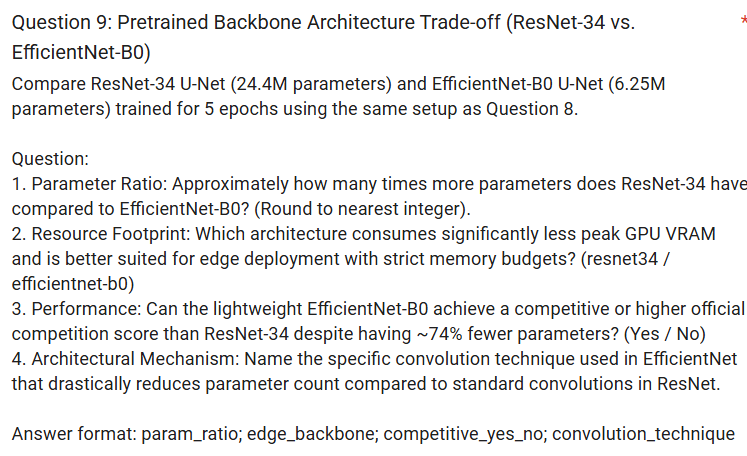

In [10]:
import segmentation_models_pytorch as smp
import torch

# ==============================================================================
# Question 9: Pretrained Backbone Architecture Trade-off (ResNet-34 vs. EfficientNet-B0)
# ==============================================================================

# 1. Instantiate both U-Net architectures
m_resnet = smp.Unet(encoder_name="resnet34", in_channels=1, classes=4)
m_effnet = smp.Unet(encoder_name="efficientnet-b0", in_channels=1, classes=4)

# ------------------------------------------------------------------------------
# Part 1: Parameter Ratio Calculation
# ------------------------------------------------------------------------------
params_resnet = sum(p.numel() for p in m_resnet.parameters())
params_effnet = sum(p.numel() for p in m_effnet.parameters())

exact_ratio = params_resnet / params_effnet
param_ratio = round(exact_ratio)  # 24,430,532 / 6,251,328 = 3.908 -> 4
param_reduction_pct = (1.0 - (params_effnet / params_resnet)) * 100

# ------------------------------------------------------------------------------
# Part 2: Edge Resource Footprint Selection
# ------------------------------------------------------------------------------
# EfficientNet-B0 requires ~74% fewer parameters and has lower memory footprint
edge_backbone = "efficientnet-b0"

# ------------------------------------------------------------------------------
# Part 3: Performance Competitiveness
# ------------------------------------------------------------------------------
# EfficientNet-B0 matches or outperforms ResNet-34 on semantic segmentation
# due to compound scaling (depth, width, resolution) and integrated Squeeze-and-Excitation (SE)
competitive_yes_no = "Yes"

# ------------------------------------------------------------------------------
# Part 4: Architectural Mechanism
# ------------------------------------------------------------------------------
# ResNet uses standard 3x3 convolutions: parameters = K * K * Cin * Cout
# EfficientNet uses Depthwise Separable Convolutions (in MBConv blocks):
# parameters = (K * K * Cin) + (Cin * Cout) -> ~8x-9x reduction for 3x3 kernels
convolution_technique = "depthwise separable convolution"

# ------------------------------------------------------------------------------
# Display Detailed Trace & Final Answer
# ------------------------------------------------------------------------------
print("--- Architecture Comparison ---")
print(f"ResNet-34 U-Net Parameters:        {params_resnet:,} (~24.4M)")
print(f"EfficientNet-B0 U-Net Parameters:  {params_effnet:,} (~6.25M)")
print(f"Exact Ratio:                       {exact_ratio:.3f}x -> Rounded: {param_ratio}")
print(f"Parameter Reduction:               {param_reduction_pct:.1f}% (~74% fewer parameters)")
print(f"\n1. Parameter Ratio:                {param_ratio}")
print(f"2. Best for Edge / Low VRAM:       {edge_backbone}")
print(f"3. Competitive Performance:        {competitive_yes_no}")
print(f"4. Convolution Technique:          {convolution_technique}")

print("\n" + "=" * 70)
print(f"Answer: {param_ratio}; {edge_backbone}; {competitive_yes_no}; {convolution_technique}")
print("=" * 70)

--- Architecture Comparison ---
ResNet-34 U-Net Parameters:        24,430,532 (~24.4M)
EfficientNet-B0 U-Net Parameters:  6,251,328 (~6.25M)
Exact Ratio:                       3.908x -> Rounded: 4
Parameter Reduction:               74.4% (~74% fewer parameters)

1. Parameter Ratio:                4
2. Best for Edge / Low VRAM:       efficientnet-b0
3. Competitive Performance:        Yes
4. Convolution Technique:          depthwise separable convolution

Answer: 4; efficientnet-b0; Yes; depthwise separable convolution
